# Embedding and clustering of a model ensemble — fixed-kernel encoder, UMAP, DBSCAN, cluster viewer

This notebook runs, on one ensemble, the three steps that were spread over `2b_Encoding_with_3D_Autoencoder_topology_red.ipynb`, `test_notebook3.ipynb` and `test_notebook2_original_file.ipynb`:

1. **features** — each model $m_i$ ($i = 1, \dots, N$), a grid of $n_z \times n_y \times n_x$ density values, is mapped to a vector $\mathbf{f}_i \in \mathbb{R}^{523}$ made of 512 values from the fixed-kernel encoder of the 2b notebook, 6 topological scalars (`topo_features.py`) and 5 moments of the density distribution; the columns are standardised;
2. **embedding and clustering** — the vectors are embedded in 2D with UMAP (McInnes et al., 2018) and the embedding is clustered with DBSCAN (Ester et al., 1996), as in `test_notebook3`;
3. **cluster statistics and viewer** — for each cluster $c$, the median model $\tilde m_c(\mathbf{x}) = \mathrm{median}_{i \in c}\, m_i(\mathbf{x})$ and the standard-deviation model $s_c(\mathbf{x}) = \big(\frac{1}{|c|}\sum_{i \in c} (m_i(\mathbf{x}) - \bar m_c(\mathbf{x}))^2\big)^{1/2}$, where $\bar m_c$ is the mean model and $|c|$ the number of members, are computed and shown in tile views and in a self-contained interactive page (Bokeh), in the spirit of the linked-brushing mosaic of `test_notebook2`.

### Data

With `USE_SYNTHETIC = True`, the ensemble is the synthetic stand-in of the motif workflow (`synthetic_ensemble.py`, as in `motif_workflow_boulia_v2.ipynb`): three chains of undercover models (cover / sediments / basement, with sampled unit densities) with born lenses, dykes and pipes and basement highs of random geometry, and a truth table recording what was drawn in each model. The truth table is used at the end to read the clusters. With `USE_SYNTHETIC = False`, the Boulia file is loaded as in the other notebooks.

Shapes: `core` is the analysis region, $(n_z, n_y, n_x, N)$ with depth along axis 0 (index 0 at the top) and the model index last, the lateral padding of the inversion grid removed; all features are computed on it. The ensemble is held in memory as float32, about 0.31 MB per synthetic model ($36 \times 42 \times 52$ cells), i.e. 3.1 GB for 10 000 models; the per-cluster statistics and the viewer add little to this. Sections are named by the axis held fixed: the section at $y = i_y$ is an $x$–$z$ panel, the section at $x = i_x$ a $y$–$z$ panel, the map at $z = i_z$ an $x$–$y$ panel.

### The encoder

The encoder of the 2b notebook has no trained weight: it applies 351 fixed $3 \times 3 \times 3$ difference kernels (one per unordered pair of voxels of the neighbourhood, $+1/\sqrt{2}$ at one voxel and $-1/\sqrt{2}$ at the other), takes the absolute value and max-pools, three times (the second and third blocks depthwise), average-pools the output of each block, projects each pooled output on a fixed random column-orthonormal basis (128, 128 and 256 dimensions; Johnson & Lindenstrauss, 1984) and $L_2$-normalises each branch. The response of a difference kernel is non-zero only across unit contacts, so the features measure the position and density of the interfaces at three scales. `ensemble_features.py` computes it with NumPy by shifting the grid instead of convolving it, with the same flatten order and the same random seeds as the TensorFlow model, so that no GPU and no TensorFlow are needed; `ef.check_against_convolution()` compares it with a brute-force convolution (agreement to $10^{-7}$, float32 rounding).

All parameters are set in the cells where they are used and named in capitals. Cells are meant to be run from top to bottom. Modules: `synthetic_ensemble.py` (data), `ensemble_features.py` (features), `cluster_tools.py` (embedding, clustering, statistics, figures), `cluster_viewer.py` (interactive page), `topo_features.py` (topological features).

### Running in Google Colab

Open the notebook with the *Open in Colab* link of the repository and run the first cell: it clones the repository (notebook and modules) into the Colab session, moves into it and installs the packages that Colab lacks. The cell does nothing when the notebook runs locally. Files written by the notebook stay in the Colab session and are lost when it ends; download them from the file panel on the left if needed.

In [1]:
# --- Google Colab only: get the modules and install the packages (skipped when run locally) ---
import sys, os
IN_COLAB = 'google.colab' in sys.modules
REPO_URL = 'https://github.com/<user>/<repo>.git'   # <-- repository holding this notebook and its modules
REPO_SUBDIR = ''                                     # folder of the notebook inside the repository ('' = root)

if IN_COLAB:
    repo_dir = '/content/' + REPO_URL.rstrip('/').split('/')[-1].removesuffix('.git')
    if not os.path.isdir(repo_dir):
        !git clone -q --depth 1 {REPO_URL} {repo_dir}
    %cd {os.path.join(repo_dir, REPO_SUBDIR)}
    %pip install -q umap-learn connected-components-3d colorcet "bokeh>=3.4"
print("Colab:", IN_COLAB, "| working directory:", os.getcwd())

Colab: False | working directory: c:\Users\00090846\OneDrive - UWA\Desktop\ppt pres\ASEG2026 Short Course\github_repo\PostTopo


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from time import time
from importlib import reload

import ensemble_features as ef
import cluster_tools as ct
import cluster_viewer as cv
for m_ in (ef, ct, cv):
    reload(m_)

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
plt.rcParams['figure.dpi'] = 110
print("Imports: completed.")

Imports: completed.


## Data

In [3]:
USE_SYNTHETIC = False
MAX_NUM_MODELS = None        # cap on the number of models (None = all), evenly spread over the ensemble
FILE_PREFIX = 'synthetic_3chains'   # prefix of the files written by this notebook (features, embedding, viewer)

if USE_SYNTHETIC:
    import synthetic_ensemble as se
    N_PER_CHAIN = 1000        # models per chain; 3 chains -> 3 x N_PER_CHAIN models (about 0.31 MB of RAM per model)
    padd = 6
    # the lateral padding is dropped as each model is generated: core is built directly, without a full-size copy
    core, chain_id, data_misfit, truth = se.make_ensemble(n_per_chain=N_PER_CHAIN, padd=padd, seed=0,
                                                          return_truth=True, crop_padding=True)
else:
    # --- Boulia: post-burn-in models saved once by the export cell (export_boulia_subset_cell.py): the same number
    #     of models from each chain, evenly spaced after burn-in, lateral padding removed, axes (depth, y, x, model) ---
    FIELD_FILE = 'boulia_5chains_2000models.npz'   # in the notebook folder (or the cloned repository in Colab)
    with np.load(FIELD_FILE) as d:
        core, chain_id, padd = d['models'].astype(np.float32, copy=False), d['chain_id'], int(d['padd'])
        print(f"{FIELD_FILE}: {core.shape[3]} models from {len(d['chains'])} chains, stored models from "
              f"{int(d['burn_in'])} (burn-in) on, lateral padding of {padd} cells removed")
    core = core[::-1, :, :]
    core = np.swapaxes(core, 2, 1)

    truth = None
    data_misfit = np.full(core.shape[3], np.nan)
    FILE_PREFIX = 'boulia_5chains'

if MAX_NUM_MODELS is not None and MAX_NUM_MODELS < core.shape[3]:
    keep = np.unique(np.linspace(0, core.shape[3] - 1, MAX_NUM_MODELS).round().astype(int))
    core, chain_id, data_misfit = np.ascontiguousarray(core[..., keep]), chain_id[keep], data_misfit[keep]
    if truth is not None:
        truth = truth.iloc[keep].reset_index(drop=True)

nz, ny, nx, N = core.shape
print(f"core (padding removed): {core.shape}, {core.nbytes / 1e9:.2f} GB")
print("chains:", dict(zip(*np.unique(chain_id, return_counts=True))))
if truth is not None:
    print("bodies drawn (fraction of models):", truth[['high', 'lens', 'dyke', 'pipe']].mean().round(2).to_dict())

boulia_5chains_2000models.npz: 2000 models from 5 chains, stored models from 2500 (burn-in) on, lateral padding of 12 cells removed
core (padding removed): (30, 30, 70, 2000), 0.50 GB
chains: {np.str_('20240411_field_re_5869'): np.int64(400), np.str_('20240416_field_re_4192'): np.int64(400), np.str_('20240428_field_re_4493'): np.int64(400), np.str_('20240903_field_re_758'): np.int64(400), np.str_('20241106_field_re_9108'): np.int64(400)}


In [4]:
# --- rename the chains 'chain 1', 'chain 2', ..., numbered in order of first appearance in the ensemble ---
_, first, inv = np.unique(chain_id, return_index=True, return_inverse=True)
labels = np.array([f'chain {k + 1}' for k in range(len(first))])
chain_id = labels[np.argsort(np.argsort(first))][inv.ravel()]

## Features

The three groups of features are computed on `core`: the encoder on the densities scaled to $[0, 1]$ with the global minimum and maximum of the ensemble (as in the 2b notebook), the topological scalars and the density moments on the raw values. The result is standardised column by column (`StandardScaler`), so that the 512 encoder values, which are small and correlated, do not swamp the 11 others, and saved with the same file names as in the 2b notebook. The encoder takes about 0.1 s per model of $36 \times 42 \times 52$ cells and per core, and the models are spread over all cores (`n_jobs=-1`); the random projections are built once (about 15 s, with a transient 1.8 GB of memory). Memory does not grow with the number of models beyond the ensemble itself: each worker receives only its batch of models (about 0.25 GB per worker). If memory is short on a machine with many cores, pass `n_jobs=4` (for example) to both calls.

In [5]:
t0 = time()
enc = ef.DiffNetEncoder(core.shape[:3])                 # fixed random projections for this grid (seeds 1, 2, 3)
print(f"encoder: pooled dimensions {enc.in_dims} -> {enc.dims} ({time() - t0:.1f} s to build the projections)")

t0 = time()
latent_codes = enc.encode_ensemble(core, n_jobs=-1)     # (N, 512)
print(f"latent codes: {latent_codes.shape} in {time() - t0:.0f} s")

t0 = time()
topo, features_density = ef.topo_and_density_features(core, n_jobs=-1)    # (N, 6), (N, 5)
print(f"topological and density features: {topo.shape}, {features_density.shape} in {time() - t0:.0f} s")

features, scaler = ef.combine_features(latent_codes, topo, features_density)   # (N, 523), standardised
print("combined features:", features.shape)

np.save(f"{FILE_PREFIX}_features_latent_codes.npy", latent_codes)
np.save(f"{FILE_PREFIX}_topo.npy", topo)
np.save(f"{FILE_PREFIX}_features_density.npy", features_density)
np.save(f"{FILE_PREFIX}_features.npy", features)
pd.DataFrame(np.hstack([topo, features_density]), columns=ef.TOPO_FEATURE_NAMES + ef.DENSITY_FEATURE_NAMES).describe().round(3)

encoder: pooled dimensions (292383, 25272, 1404) -> (128, 128, 256) (6.6 s to build the projections)
latent codes: (2000, 512) in 87 s
topological and density features: (2000, 6), (2000, 5) in 13 s
combined features: (2000, 523)


,k,total_cc,fiedler_w,he_entropy,mean_herfindahl,mean_ellipticity,density_mean,density_std,density_skew,density_kurtosis,density_range
count,2000.000,2000.000,2000.000,2000.000,2000.000,2000.000,2000.000,2000.000,2000.000,2000.000,2000.000
mean,7.021,33.145,1000.216,7.935,0.861,0.879,9.969,40.599,0.961,3.797,233.297
std,1.641,19.926,621.029,0.556,0.058,0.045,0.896,3.553,0.762,1.874,38.867
min,5.000,6.000,5.618,6.168,0.667,0.675,6.204,30.557,-1.398,0.316,123.180
25%,6.000,16.000,506.331,7.553,0.822,0.850,9.433,38.480,0.429,2.471,205.847
50%,6.000,31.000,893.265,7.865,0.859,0.885,9.989,40.953,0.894,3.301,227.961
75%,7.000,45.000,1396.074,8.217,0.899,0.914,10.542,43.170,1.397,4.637,254.769
max,17.000,150.000,3164.397,10.196,1.000,0.964,13.560,51.970,2.751,12.715,405.536


## UMAP embedding

The parameters are those of the 2b notebook: `n_neighbors = 5` (local structure; the embedding then forms thin strings of neighbouring models rather than blobs), `min_dist = 0.01` (tight packing), cosine metric on the standardised features, fixed seed. The embedding is saved as a CSV with the columns `comp_1`, `comp_2` followed by the features, as the 2b notebook writes it, so that `test_notebook3` can read it.

c:\Users\00090846\AppData\Local\miniconda3\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP: (2000, 2) in 46 s
saved: boulia_5chains_umap_5Features_cnn_topo_dens_DiffNN_0.05_metrics_cosine__.csv


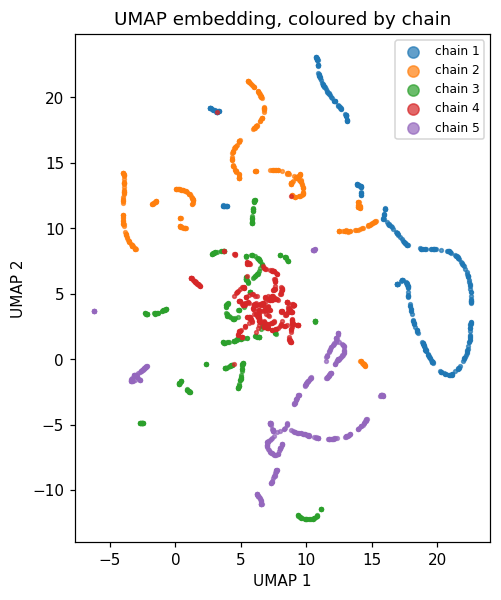

In [6]:
# neighbourhood size used to build the graph: 
# small (2–5) keeps local structure (thin strings of near-identical models), 
# large (15–50) favours global structure (broader blobs)
UMAP_N_NEIGHBORS = 5        

# minimum spacing of points in the 2D embedding: 
# small (0.0–0.05) packs similar models tightly (good for clustering), 
# large (0.1–0.5) spreads them out (easier to read)
UMAP_MIN_DIST = 0.05 

 # distance between feature vectors: 'cosine' (angle, ignores vector length), 
 # 'euclidean' (UMAP default), 
 # 'correlation' (cosine after centring each vector), 
 # 'manhattan' (sum of absolute differences, less sensitive to a few large values)
UMAP_METRIC = 'cosine'     

t0 = time()
coords, reducer = ct.umap_embed(features, n_neighbors=UMAP_N_NEIGHBORS, min_dist=UMAP_MIN_DIST, metric=UMAP_METRIC,
                                random_state=42)
print(f"UMAP: {coords.shape} in {time() - t0:.0f} s")

df_umap = pd.concat([pd.DataFrame(coords, columns=['comp_1', 'comp_2']), pd.DataFrame(features)], axis=1)
umap_csv = f"{FILE_PREFIX}_umap_{UMAP_N_NEIGHBORS}Features_cnn_topo_dens_DiffNN_{UMAP_MIN_DIST}_metrics_{UMAP_METRIC}__.csv"
df_umap.to_csv(umap_csv, index=False)
print("saved:", umap_csv)

fig, ax = plt.subplots(figsize=(7, 6))
for c in np.unique(chain_id):
    m = chain_id == c
    ax.scatter(coords[m, 0], coords[m, 1], s=6, alpha=0.7, label=c)
ax.set_aspect('equal'); ax.legend(markerscale=3, fontsize=8); ax.set_xlabel('UMAP 1'); ax.set_ylabel('UMAP 2')
ax.set_title('UMAP embedding, coloured by chain')
plt.show()


## Clustering

DBSCAN groups the points of the embedding that are chained by neighbours closer than `EPS`, with at least `MIN_SAMPLES` neighbours for a point to be a core point; points reachable from no core point are noise (label $-1$). `EPS` is in embedding units and depends on $N$ and on the UMAP parameters: the $k$-distance curve (distance of each point to its `MIN_SAMPLES`-th neighbour, sorted) gives the usual choice, at the knee of the curve, and the cell prints the number of clusters and of noise points for a few values before using `EPS`. Setting `CLUSTERER = 'hdbscan'` uses HDBSCAN instead (Campello et al., 2013), which needs no `EPS` but a minimum cluster size.

eps = 0.2   -> 175 clusters,  136 noise points
eps = 0.3   -> 125 clusters,   20 noise points
eps = 0.35  -> 100 clusters,   12 noise points
eps = 0.5   ->  55 clusters,    8 noise points
eps = 0.75  ->  40 clusters,    8 noise points


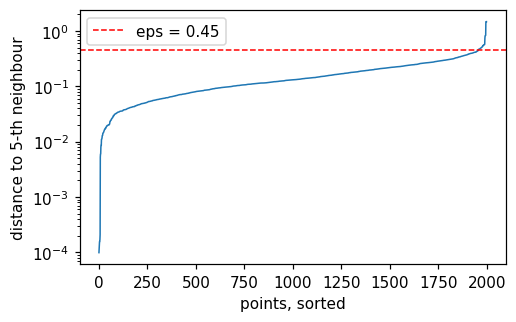

dbscan: 70 clusters, 8 noise points, N = 2000


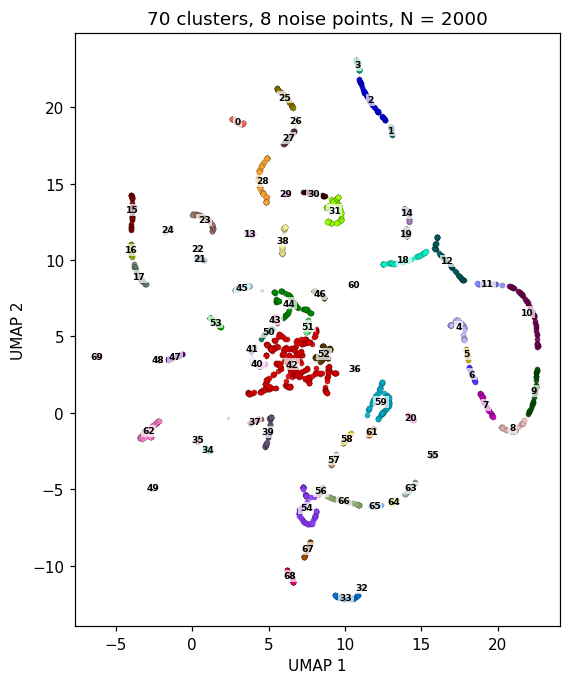

In [7]:
# clustering method: 'dbscan' (fixed density threshold set by EPS; must be tuned per ensemble) 
# or 'hdbscan' (adapts to clusters of varying density, no EPS to choose, but tends to merge the thin UMAP strings)
CLUSTERER = 'dbscan'   

 # DBSCAN only: radius of the neighbourhood in embedding units; 
 # smaller (0.2–0.3) gives more, smaller clusters and more noise, 
 # larger (0.5–0.75) merges clusters; choose near the knee of the k-distance curve
EPS = 0.45  

# DBSCAN: number of points within EPS for a point to be a core point; 
# HDBSCAN: how conservative the density estimate is; 
# small (3–5) keeps small clusters, 
# large (10–20) leaves more points as noise; 
MIN_SAMPLES = 5  
           
# HDBSCAN only: smallest group of models accepted as a cluster; 
# small (5–10) gives many fine clusters, large (20–50) only the main families
MIN_CLUSTER_SIZE = 10       

for eps in (0.2, 0.3, 0.35, 0.5, 0.75):
    n_cl, n_noise = ct.cluster_summary(ct.cluster_dbscan(coords, eps=eps, min_samples=MIN_SAMPLES))
    print(f"eps = {eps:<5} -> {n_cl:3d} clusters, {n_noise:4d} noise points")
ct.plot_kdist(coords, k=MIN_SAMPLES, eps=EPS)
plt.show()

if CLUSTERER == 'dbscan':
    labels = ct.cluster_dbscan(coords, eps=EPS, min_samples=MIN_SAMPLES)
else:
    labels = ct.cluster_hdbscan(coords, min_cluster_size=MIN_CLUSTER_SIZE, min_samples=MIN_SAMPLES)
n_clusters, n_noise = ct.cluster_summary(labels)
print(f"{CLUSTERER}: {n_clusters} clusters, {n_noise} noise points, N = {N}")
np.save(f"{FILE_PREFIX}_cluster_labels.npy", labels)

ct.plot_embedding(coords, labels, min_size=MIN_SAMPLES)
plt.show()

### Cluster table

One row per cluster, sorted by size: number of models, share of each chain, mean voxel standard deviation (the spread of the cluster in model space, in the density units of the models: small values mean that the members are nearly the same model), index of the representative model (the member closest to the cluster centroid in the embedding), and, for the synthetic ensemble, the fraction of members carrying each body. The enrichment $P(\text{body} \mid c) / P(\text{body})$ compares the frequency of a body in cluster $c$ with its frequency in the whole ensemble, as done with motifs in the motif workflow: a value well above 1 identifies what the cluster is made of, a value near 0 what it excludes.

In [8]:
tab = ct.cluster_table(core, coords, labels, chain_id, truth=truth, min_size=MIN_SAMPLES)
display(tab.round(2).head(20))
if truth is not None:
    enr = ct.truth_enrichment(truth, labels, min_size=MIN_SAMPLES)
    display(enr.round(2).head(20))

,n,frac_chain 1,frac_chain 2,frac_chain 3,frac_chain 4,frac_chain 5,mean_voxel_std,representative
cluster,,,,,,,,
42,335,0.0,0.00,0.21,0.79,0.0,19.09,1218
54,65,0.0,0.00,0.00,0.00,1.0,13.43,1916
44,62,0.0,0.00,0.55,0.45,0.0,18.03,1020
59,61,0.0,0.00,0.00,0.00,1.0,13.40,1697
31,58,0.0,0.98,0.00,0.02,0.0,12.69,754
62,51,0.0,0.00,0.00,0.00,1.0,11.41,1798
10,47,1.0,0.00,0.00,0.00,0.0,11.92,272
28,46,0.0,1.00,0.00,0.00,0.0,13.07,694
52,46,0.0,0.00,0.00,1.00,0.0,18.02,1521


## Cluster statistics: tile views and sections

The tile views show one section of the median model of every cluster (clusters sorted by size, as in `test_notebook3`), and the same for the standard-deviation model. `IY`, `IX`, `IZ` are the indices of the sections used here and in the viewer; for the synthetic ensemble, the basement high is centred near $y \approx 18$, $x \approx 16$ of `core` and the pipe near $y \approx 26$, $x \approx 39$, so `IY = 22` passes between them and the depth map at `IZ = 10` cuts the lenses, dykes, pipes and most basement highs.

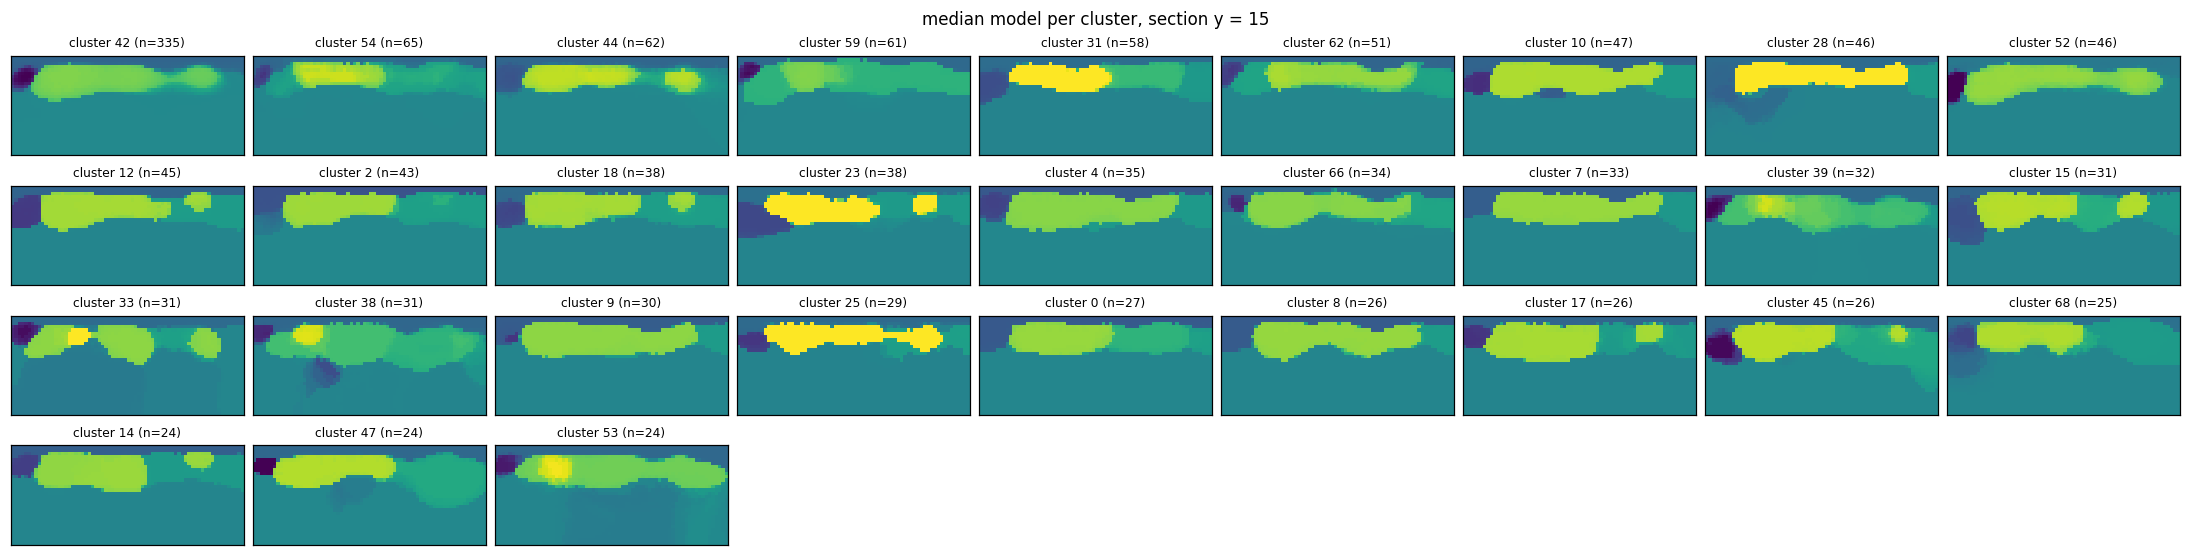

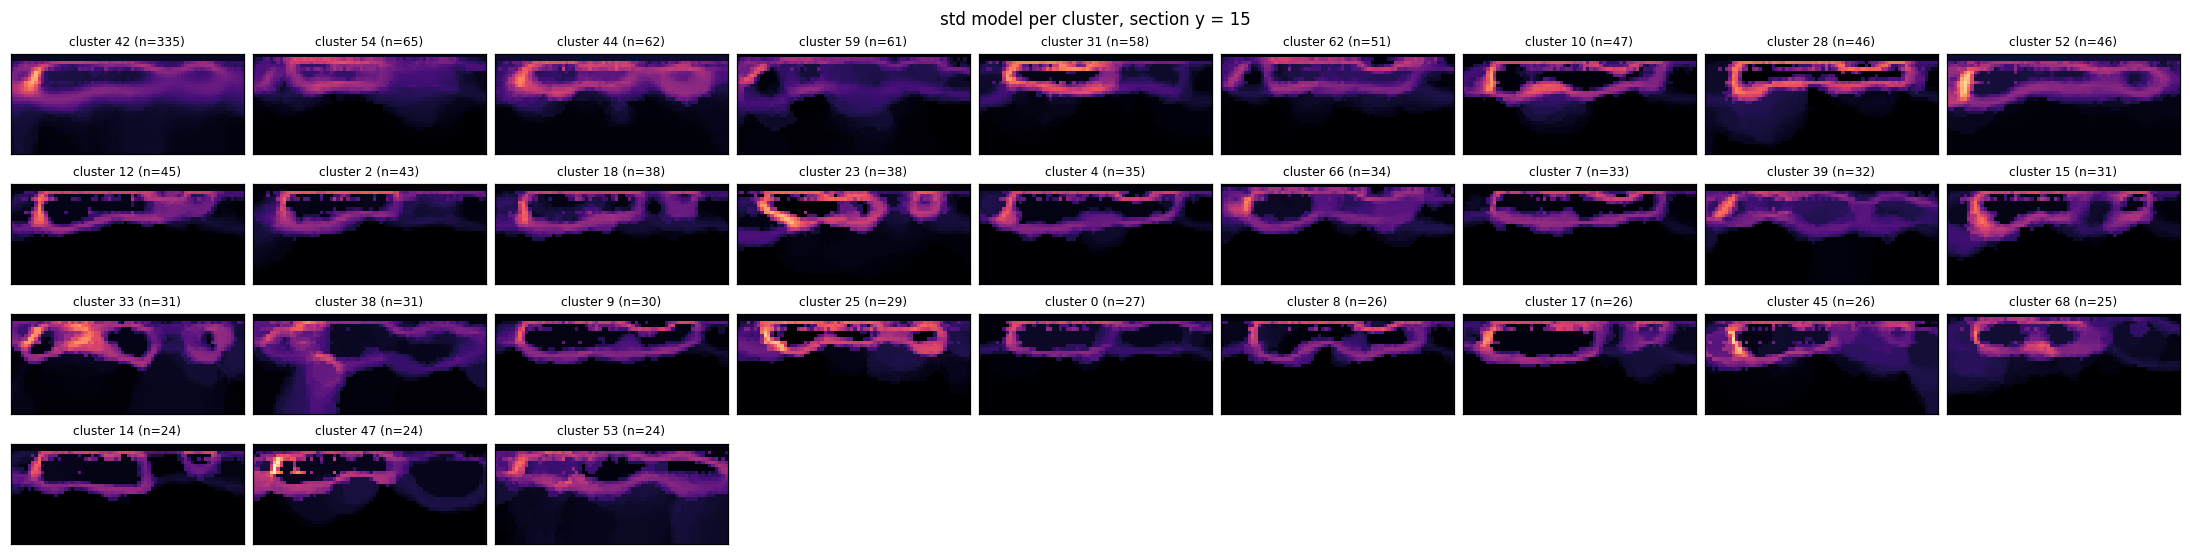

In [ ]:
nz, ny, nx, N = core.shape
if USE_SYNTHETIC:      # section indices in core (y = IY: x-z panel; x = IX: y-z panel; z = IZ: x-y map)
    IY, IX, IZ = 22, ny // 2, 10
else:
    IY, IX, IZ = ny // 2, nx // 2, 10

AXIS_COORDS = None
AXIS_UNITS = 'cell'

VMIN, VMAX = np.percentile(core[..., ::max(N // 200, 1)], [0.5, 99.5])   # common colour scale for densities

fig = ct.plot_cluster_tiles(core, labels, orient='y', iy=IY, stat='median', min_size=MIN_SAMPLES, max_tiles=30,
                            vmin=VMIN, vmax=VMAX, axis_coords=AXIS_COORDS, units=AXIS_UNITS)
fig.savefig(f"{FILE_PREFIX}_cluster_tiles_median_y{IY}.png", dpi=200, bbox_inches='tight')
plt.show()
fig = ct.plot_cluster_tiles(core, labels, orient='y', iy=IY, stat='std', min_size=MIN_SAMPLES, max_tiles=30,
                            vmin=0, cmap='magma', axis_coords=AXIS_COORDS, units=AXIS_UNITS)
plt.show()


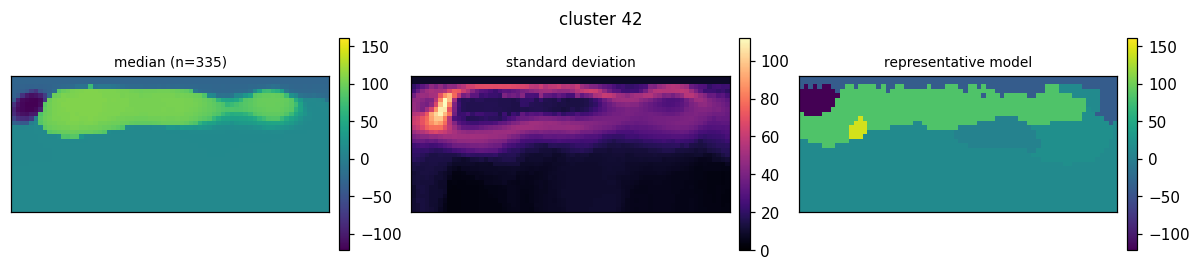

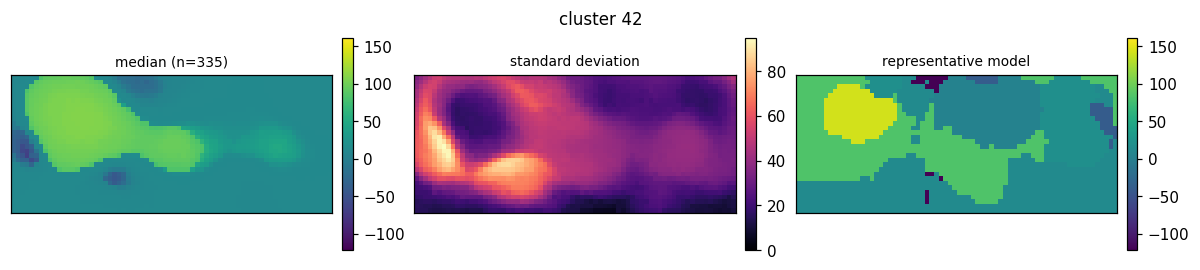

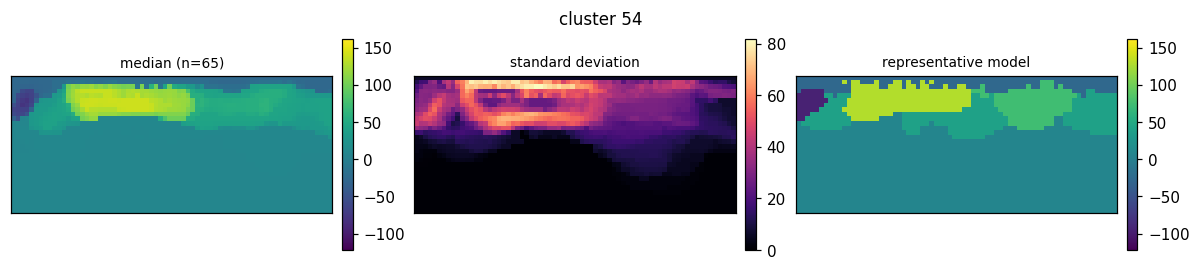

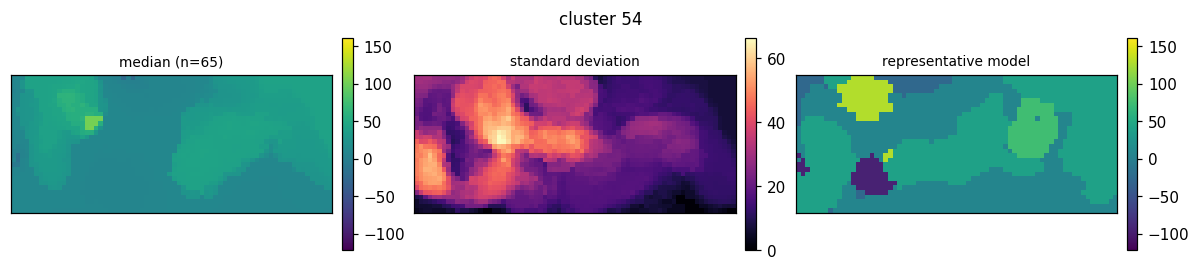

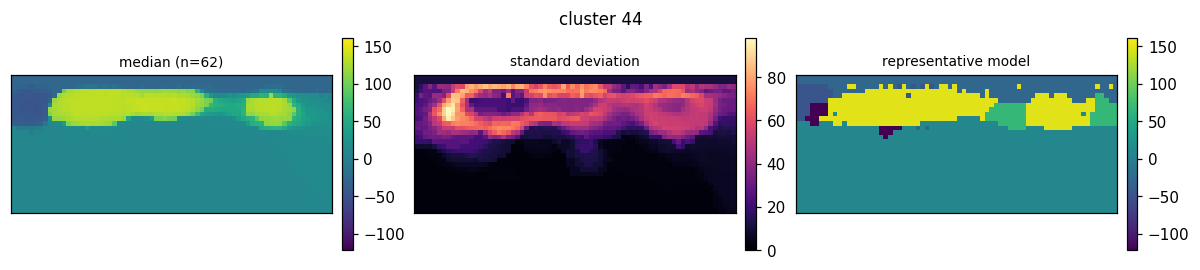

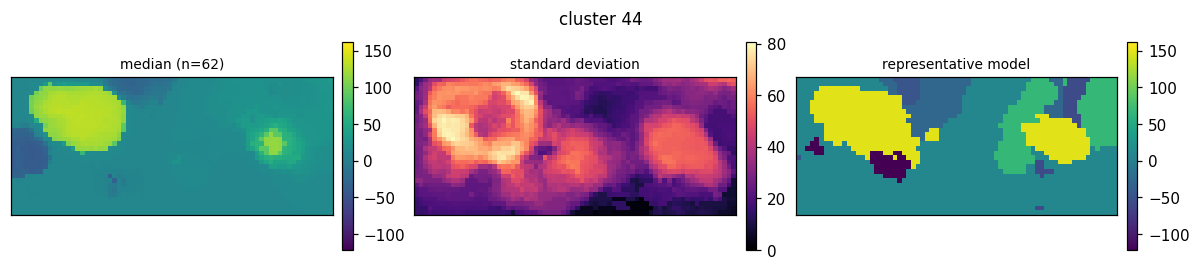

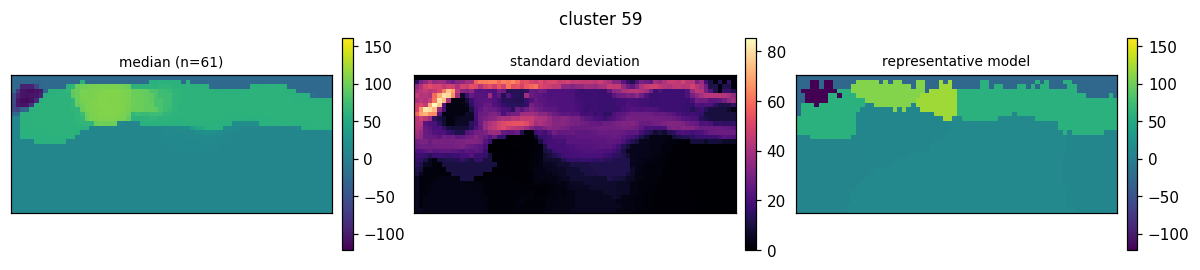

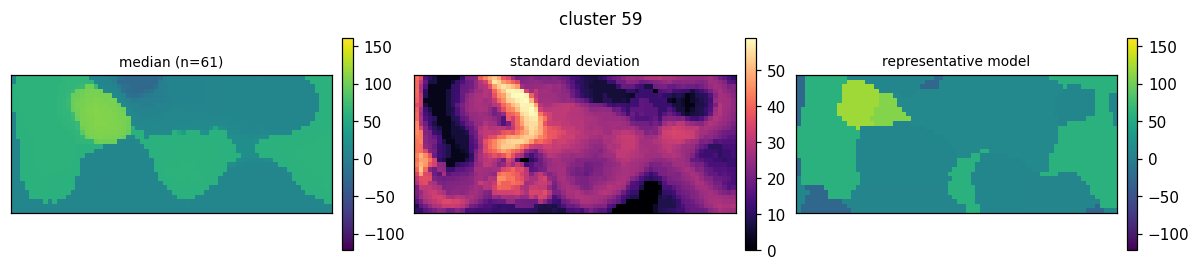

In [10]:
# Median, standard deviation and representative model of the largest clusters, on the y section and on the depth map.
N_SHOW = 4
for cl in ct.cluster_ids_by_size(labels, MIN_SAMPLES)[:N_SHOW]:
    for orient in ('y', 'z'):
        fig = ct.plot_cluster_sections(core, coords, labels, cl, orient=orient, iy=IY, ix=IX, iz=IZ,
                                       vmin=VMIN, vmax=VMAX)
        plt.show()

## Interactive viewer

`cluster_viewer.build_viewer` writes a self-contained HTML page: the embedding coloured by cluster (hover: the $y$ section of the model under the cursor, its cluster, its chain and, for the synthetic ensemble, the bodies it contains; tap: select the cluster), a drop-down list of the clusters sorted by size, a choice of section ($y$, $x$ or depth map), the median, standard-deviation and representative models of the selected cluster on that section, and the cluster table. Clusters with fewer than `MIN_SAMPLES` models are shown as grey points but not listed. The saved page is embedded below the cell (open the HTML file in a browser for a full-size view); in Colab, the viewer is drawn in the notebook directly.

In [11]:
viewer_html = f"{FILE_PREFIX}_cluster_viewer_strings.html"
layout = cv.build_viewer(core, coords, labels, chain_id, iy=IY, ix=IX, iz=IZ, truth=truth,
                         min_size=MIN_SAMPLES, max_clusters=60, vmin=VMIN, vmax=VMAX,
                         title=f'{FILE_PREFIX}: {n_clusters} clusters ({CLUSTERER})')
cv.save_viewer(layout, viewer_html, title=f'{FILE_PREFIX} cluster viewer')
print("saved:", viewer_html, f"({os.path.getsize(viewer_html) / 1e6:.1f} MB)")
if IN_COLAB:                       # Colab cannot serve a local file to the browser: show the layout itself
    from bokeh.io import output_notebook, show
    output_notebook(hide_banner=True)
    show(layout)
    # from google.colab import files; files.download(viewer_html)   # to keep the standalone page
else:
    from IPython.display import IFrame
    display(IFrame(viewer_html, width=1250, height=1150))   # the saved page; open the file for a full-size view

saved: boulia_5chains_cluster_viewer_strings.html (5.2 MB)


## Notes

- **Features.** The encoder has no trained weight, so its output is reproducible across machines and ensembles; the 0–1 scaling uses the global extrema of the ensemble, so that two ensembles with different density ranges are not directly comparable in feature space unless scaled with the same `vmin`, `vmax` (`encode_ensemble` accepts them). The features are computed on `core`; set `padd = 0` to include the padding cells, as the 2b notebook did on the full Boulia grid.
- **Embedding.** UMAP with `n_neighbors = 5` preserves local structure: the strings seen in the embedding are chains of models that differ by one small change, not clusters in the usual sense, and DBSCAN with a small `EPS` cuts them where the chain is interrupted. A larger `n_neighbors` (15–30) gives blob-like clusters at the cost of the fine structure. The embedding is not deterministic across UMAP versions even with a fixed seed.
- **Clustering.** `EPS` must be chosen for each ensemble (the $k$-distance curve and the table of counts above); the same value gives different numbers of clusters for different $N$ and different UMAP parameters. HDBSCAN removes this choice but tends to merge the strings.
- **Reading the clusters.** With the synthetic ensemble, the enrichment table shows which bodies each cluster is made of. On a real ensemble, the motif enrichment of the motif workflow (`ma.cluster_enrichment(df, labels)`) plays the same role; the labels saved by this notebook (`<prefix>_cluster_labels.npy`) are the `labels_all` that the motif notebook expects, provided both run on the same `core` and the same model order.

### References

- Campello, R.J.G.B., Moulavi, D. & Sander, J., 2013. Density-based clustering based on hierarchical density estimates, *PAKDD*, LNCS 7819, 160–172.
- Ester, M., Kriegel, H.-P., Sander, J. & Xu, X., 1996. A density-based algorithm for discovering clusters in large spatial databases with noise, *Proc. KDD-96*, 226–231.
- Johnson, W.B. & Lindenstrauss, J., 1984. Extensions of Lipschitz mappings into a Hilbert space, *Contemp. Math.*, 26, 189–206.
- McInnes, L., Healy, J. & Melville, J., 2018. UMAP: Uniform Manifold Approximation and Projection for dimension reduction, arXiv:1802.03426.

## Motifs and topology of the clusters

The clusters found above are read with the motif analysis of the motif workflow (`motif_analysis.py`, as in `motif_workflow_boulia_v4.ipynb`). Each model $m_i$ is turned into its body graph (bodies are 6-connected sets of cells of one unit, linked by their contacts; Thiele et al., 2016a) and into a vector of motif counts $c_k(m_i)$, the number of bodies of $m_i$ realising motif $k$ (`enclosed_body`, `layer`, `steep_body`, `cross_cutting`, `dyke`, `bridge`, `chimney`, `window`, `order_violation`; `fragment` counts the bodies below the volume floor). The motifs, their thresholds and their geological reading are defined in the motif workflow.

For a cluster $c$ with $|c|$ models and a motif $k$,

$$P(k \mid c) = \frac{1}{|c|}\sum_{i \in c}\mathbf{1}\{c_k(m_i) > 0\}, \qquad P(k) = \frac{1}{N}\sum_{i=1}^{N}\mathbf{1}\{c_k(m_i) > 0\}, \qquad E_{kc} = \frac{P(k \mid c)}{P(k)},$$

where $P(k \mid c)$ is the fraction of the models of the cluster that hold the motif, $P(k)$ the same fraction over the whole ensemble ($N$ models, noise included) and $E_{kc}$ the enrichment, as in `ma.cluster_enrichment`. $E_{kc} \gg 1$ marks the configurations that characterise the cluster, $E_{kc} \approx 0$ those it excludes (over-representation against a null model, Milo et al., 2002). The clusters come from the encoder, topological and density features, not from the motif counts, so that the enrichment is an independent interpretation of the clusters rather than a restatement of them.

The topology key $T(m)$ (unit-level contacts and number of bodies per unit, capped at `MAX_BODIES`, born units grouped; Thiele et al., 2016b) is computed with the motifs. The classes are numbered by decreasing frequency in the ensemble, as in the census of the motif workflow (`ma.topology_census`): class #1 is the most frequent topology.

**Settings and reference model.** The parameters of the next cell are those of the parameters cell of the motif workflow and should be given the same values, so that both notebooks count the same motifs. Units are matched across models by spatial overlap with a reference model (label switching; Stephens, 2000): for the synthetic ensemble, the prior model of the generator; for Boulia, the prior model of the sampler saved from the motif workflow (`PRIOR_FILE`). `cm.reference_model` (`cluster_motifs.py`) brings the prior to the grid of `core` by removing its lateral padding and choosing the axis order and flips whose units agree best with the models, as `eio.find_prior_orientation` does in the motif workflow, so that the transformations of the data cell need not be repeated; without a prior, it builds a modal stand-in from the ensemble (`ma.modal_reference`). Reference units occupying less than `MIN_UNIT_SHARE` of the grid are absorbed by their nearest unit.

**Second viewer.** The page saved as `<prefix>_cluster_viewer_motifs.html` adds to the first one: the motifs, number of units and born units and topology class of the model under the cursor; a menu colouring the embedding by cluster, by chain or by the presence of one motif; for the selected cluster, the enriched ($E \ge 2$) and depleted ($E \le 0.5$, for motifs present in at least 5 % of the ensemble) motifs, $P(k \mid c)$ and $E_{kc}$ for every motif, its most frequent topology class, and the cluster means of the number of units and of the topological features; a heatmap of $E_{kc}$ on a logarithmic colour scale (clusters × motifs; tap a row to select the cluster); and $E_{kc}$ and topology columns in the cluster table (horizontal scroll bar).

In [12]:
import motif_analysis as ma
import motif_plots as mp
import cluster_motifs as cm
for m_ in (ma, mp, cm):
    reload(m_)

# ---------- Motif settings: use the values of the parameters cell of motif_workflow_boulia_v4.ipynb ----------
VMIN_VOXELS = 8           # volume floor V_min: bodies with fewer voxels are fragments (sampler noise)
MAX_BODIES = 5            # topology key: bodies per unit counted up to this value (fragmentation of units)
ORDER = None              # stratigraphic order of reference codes, top -> bottom; None = all, by mean depth
MIN_UNIT_SHARE = 0.01     # reference units below this share of the grid are absorbed by their nearest unit
CELL_SIZES = (1.0, 1.0, 1.0)   # (dz, dy, dx) in m along the axes of core (for Boulia, axes 1 and 2 are swapped in
                               # the data cell): shape, steepness and layer aspect are computed in metres
THR = dict()              # motif thresholds overriding ma.DEFAULTS, e.g. dict(c_min=1.0, amin_link=4)
UNIT_NAMES = {0: 'cover', 1: 'sediments', 2: 'basement'} if USE_SYNTHETIC else {}   # names of the reference units
VIEW_MOTIFS = [m for m in ma.MOTIFS if m != 'fragment']    # motifs in the tables and the viewer ('fragment': noise)

# Reference model. Boulia: prior model of the sampler, saved once in the motif workflow after its prior-model cell
# with np.save('boulia_prior_model.npy', prior_model); without the file, a modal stand-in is built.
PRIOR_FILE = 'boulia_prior_model.npy'
PRIOR_ROW = 0             # row of the orientation table used for the prior (0 = best); change it if the check
                          # figure shows a mirror image of the models

In [13]:
# Reference model, motif settings shared by every motif call, section viewer, and the motif table.
prior = se.prior_model() if USE_SYNTHETIC else (np.load(PRIOR_FILE) if os.path.exists(PRIOR_FILE) else None)
ref, prior_core, orient_table = cm.reference_model(core, prior, padd, min_share=MIN_UNIT_SHARE, row=PRIOR_ROW)
if orient_table is not None:
    display(orient_table.head(4).round(3))
    cm.plot_prior_check(prior_core, core, IY, IZ)        # interfaces and highs of the prior and of the models
    plt.show()
K = int(ref.max()) + 1
if not USE_SYNTHETIC and tuple(CELL_SIZES) == (1.0, 1.0, 1.0):
    print("Warning: CELL_SIZES = (1, 1, 1) is a placeholder; set the Boulia mesh (shape, steepness and layer aspect use it).")
kw = dict(vmin_voxels=VMIN_VOXELS, reference=ref, cell_sizes=CELL_SIZES, max_bodies=MAX_BODIES, order=ORDER, thr=THR)
vw = mp.Viewer(core, ref, unit_names=UNIT_NAMES, cell_sizes=CELL_SIZES)    # sections with units matched to ref

t0 = time()
df_motifs = ma.motif_table(core, n_jobs=-1, **kw)                 # one row per model, same order as core
print(f"motif table: {N} models in {time() - t0:.0f} s")
display(ma.motif_probabilities(df_motifs).T.round(3))

no prior model: modal stand-in from 200 models
reference units absorbed (< 1% of the grid): [1]
reference: 4 units (0 = top, 3 = deepest), shares of the grid: [0.187, 0.091, 0.059, 0.663]
motif table: 2000 models in 21 s


,enclosed_body,layer,steep_body,cross_cutting,dyke,bridge,chimney,window,order_violation,fragment
P_present,0.268,1.000,0.164,0.164,0.106,0.0,0.985,0.993,0.294,0.850
mean_count,0.419,1.844,0.186,0.186,0.110,0.0,2.972,1.103,0.426,20.986


In [14]:
# Per cluster (clusters with at least MIN_SAMPLES models, sorted by size): P(motif | cluster), enrichment, topology.
ids_shown = ct.cluster_ids_by_size(labels, MIN_SAMPLES)
p_cl, enr = ma.cluster_enrichment(df_motifs, labels)
print("P(motif | cluster):")
display(p_cl.loc[ids_shown, ['n_models'] + VIEW_MOTIFS].round(2))
print("enrichment E = P(motif | cluster) / P(motif)   (empty: motif absent from the ensemble)")
display(enr.loc[ids_shown, VIEW_MOTIFS].round(2).replace([np.inf, -np.inf], np.nan))

topo_class, topo_n = ct.topology_classes(df_motifs['topology'].to_numpy())   # 1 = most frequent class
print(f"{len(topo_n)} topology classes; the 5 most frequent hold "
      f"{', '.join(f'#{k + 1}: {n / N:.0%}' for k, n in enumerate(topo_n[:5]))} of the models")
display(ct.cluster_topology(topo_class, labels, MIN_SAMPLES).round(2))
if truth is not None:      # synthetic ensemble: drawn bodies (truth) next to the recovered motifs
    display(pd.concat({'drawn': ct.truth_enrichment(truth, labels, min_size=MIN_SAMPLES),
                       'recovered': enr.loc[ids_shown, ['enclosed_body', 'dyke', 'chimney', 'window']]}, axis=1).round(2))

P(motif | cluster):


,n_models,enclosed_body,layer,steep_body,cross_cutting,dyke,bridge,chimney,window,order_violation
42,335,0.22,1.0,0.14,0.14,0.08,0.0,0.96,0.99,0.15
54,65,0.46,1.0,0.14,0.14,0.06,0.0,0.98,1.00,0.37
44,62,0.52,1.0,0.29,0.29,0.16,0.0,0.97,1.00,0.23
59,61,0.28,1.0,0.30,0.30,0.23,0.0,0.93,1.00,0.07
31,58,0.45,1.0,0.00,0.00,0.00,0.0,0.97,1.00,0.66
...,...,...,...,...,...,...,...,...,...,...
29,7,0.57,1.0,0.00,0.00,0.00,0.0,1.00,1.00,0.14
56,7,0.43,1.0,0.43,0.43,0.43,0.0,1.00,1.00,0.00
69,7,0.14,1.0,0.14,0.14,0.14,0.0,1.00,1.00,0.00
22,5,0.20,1.0,0.40,0.40,0.40,0.0,1.00,1.00,0.80


enrichment E = P(motif | cluster) / P(motif)   (empty: motif absent from the ensemble)


,enclosed_body,layer,steep_body,cross_cutting,dyke,bridge,chimney,window,order_violation
42,0.82,1.0,0.88,0.88,0.79,NaN,0.98,1.00,0.50
54,1.72,1.0,0.85,0.85,0.58,NaN,1.00,1.01,1.26
44,1.93,1.0,1.78,1.78,1.52,NaN,0.98,1.01,0.77
59,1.04,1.0,1.80,1.80,2.17,NaN,0.95,1.01,0.22
31,1.67,1.0,0.00,0.00,0.00,NaN,0.98,1.01,2.23
...,...,...,...,...,...,...,...,...,...
29,2.13,1.0,0.00,0.00,0.00,NaN,1.02,1.01,0.49
56,1.60,1.0,2.62,2.62,4.04,NaN,1.02,1.01,0.00
69,0.53,1.0,0.87,0.87,1.35,NaN,1.02,1.01,0.00
22,0.75,1.0,2.45,2.45,3.77,NaN,1.02,1.01,2.73


228 topology classes; the 5 most frequent hold #1: 12%, #2: 8%, #3: 7%, #4: 4%, #5: 4% of the models


,n,topology_class,share_in_cluster,share_in_ensemble,n_classes
cluster,,,,,
42,335,1,0.20,0.12,69
54,65,23,0.14,0.01,28
44,62,3,0.18,0.07,23
59,61,1,0.34,0.12,24
31,58,11,0.12,0.02,29
...,...,...,...,...,...
29,7,2,0.29,0.08,5
56,7,2,0.29,0.08,5
69,7,2,0.71,0.08,3


In [15]:
# Second viewer: the first one plus motifs, topology classes and enrichment (saved as a separate HTML page).
VIEW_SECTION = 'y'        # vertical section in the hover and first panel: 'y' (at y = IY, along x) or 'x' (at x = IX, along y)

viewer_html_motifs = f"{FILE_PREFIX}_cluster_viewer_motifs.html"
extra = pd.concat([df_motifs[['n_units', 'n_born']], pd.DataFrame(topo, columns=ef.TOPO_FEATURE_NAMES)], axis=1)
layout_m = cv.build_viewer(core, coords, labels, chain_id, iy=IY, ix=IX, iz=IZ, truth=truth,
                           min_size=MIN_SAMPLES, max_clusters=60, vmin=VMIN, vmax=VMAX,
                           thumb_orient=VIEW_SECTION, orient=VIEW_SECTION,
                           motifs=df_motifs[VIEW_MOTIFS], topology=topo_class,
                           extra=extra, tooltip_extra=['n_units', 'n_born'],     # extra: cluster means
                           title=f'{FILE_PREFIX}: {n_clusters} clusters ({CLUSTERER}), motifs and topology')
cv.save_viewer(layout_m, viewer_html_motifs, title=f'{FILE_PREFIX} cluster viewer, motifs')
print("saved:", viewer_html_motifs, f"({os.path.getsize(viewer_html_motifs) / 1e6:.1f} MB)")
if IN_COLAB:
    from bokeh.io import output_notebook, show
    output_notebook(hide_banner=True)
    show(layout_m)
else:
    from IPython.display import IFrame
    display(IFrame(viewer_html_motifs, width=1250, height=1600))

saved: boulia_5chains_cluster_viewer_motifs.html (5.6 MB)


### Notes on the motif viewer

- **Same models, same order.** The motif table is computed here on `core`, so that row $i$ describes the model of point $i$ of the embedding; a table from the motif workflow can only be used instead if it was computed on the same models in the same order (with the Boulia subset, `chain_id` and `index_in_chain` of the `.npz` identify each model).
- **Settings.** The motif probabilities are conditional on the thresholds and on `CELL_SIZES`; the values used should be those of the motif workflow, and be reported with the results. With `CELL_SIZES = (1, 1, 1)` on the Boulia mesh, shape classes and steepness (`steep_body`, `cross_cutting`, `dyke`, `chimney`) are computed in cells, not in metres.
- **Small clusters.** $P(k \mid c)$ is a proportion over $|c|$ models, with a binomial standard error $\sqrt{P(1-P)/|c|}$ (for independent samples): for a cluster of 10 models, an enrichment of 2 for a motif present in 20 % of the ensemble rests on 4 models.
- **Topology classes** are numbered on the ensemble loaded here; the numbers differ from those of the motif workflow when the ensembles differ.

### References (this section)

- Milo, R., Shen-Orr, S., Itzkovitz, S., Kashtan, N., Chklovskii, D. & Alon, U., 2002. Network motifs: simple building blocks of complex networks, *Science*, 298(5594), 824–827.
- Stephens, M., 2000. Dealing with label switching in mixture models, *J. R. Stat. Soc. B*, 62(4), 795–809.
- Thiele, S.T., Jessell, M.W., Lindsay, M., Ogarko, V., Wellmann, J.F. & Pakyuz-Charrier, E., 2016a. The topology of geology 1: Topological analysis, *J. Struct. Geol.*, 91, 27–38.
- Thiele, S.T., Jessell, M.W., Lindsay, M., Wellmann, J.F. & Pakyuz-Charrier, E., 2016b. The topology of geology 2: Topological uncertainty, *J. Struct. Geol.*, 91, 74–87.

## Looking at the motifs: what the synthetic ensemble validates

The cells below show, for the motifs that were checked against a known geometry, an example model with its bodies, a catalogue of examples, and the probabilities of the corresponding geological hypotheses, over the whole ensemble or within one cluster of the viewer.

**How the motifs were validated.** In the motif workflow (`motif_workflow_boulia_v4.ipynb`, section *Validation against the synthetic ground truth*), the synthetic ensemble (seed 0, 1,000 models) was processed as a real one, and three fractions of models were compared for every motif and hypothesis: $P_{\text{drawn}}$, the models holding the object that was built (e.g. a pipe); $P_{\text{expected}}$, the motif definition applied to the true geometry of each model; and $P_{\text{recovered}}$, the motif found by the workflow from the sampled densities. Recovered and expected agree model by model for the number of born units, the number of bodies, the depth of the basement and the topology key, and for every motif except three models lying at a threshold (a dyke drawn 0.14° above the dip threshold, and two pieces of elongated lens between the cover and the basement classed as rods). The processing is therefore exact; what differs is how closely each definition matches the object drawn:

| Motif or quantity | Drawn object it was checked against | Result | Shown below |
|---|---|---|---|
| `chimney` | pipes from the basement into the cover | carried by 299 of the 304 pipes drawn, whatever their plunge; the others do not link the basement to the cover inside the analysis region, or are smaller than `vmin_shape` | yes |
| `dyke` | steep dykes | carried by the dykes dipping more than about 73° (`flat_cos`) | yes |
| `window` | basement highs reaching the cover | never without a basement high; misses breaches smaller than `amin_window` columns | yes |
| `enclosed_body` | lenses | carried by 56 % of the lenses: a lens truncated by the cover or the basement, or reaching a side of the region, is not enclosed (a lower bound on lenses) | yes |
| `n_born`, `z_deep_top`, topology key | born units, depth of the basement, unit contacts | identical to the truth in every model | in the hypotheses |
| `steep_body`, `cross_cutting` | dykes and pipes | carried by steep dykes and steep pipes alike (pipes alone in about 70 % of the models with `cross_cutting`) | no: not specific |
| `layer` | layers | also carried by dykes dipping less than 73° that reach the top | no |
| `bridge`, `order_violation` | none | never occur in the synthetic ensemble: not validated | no |
| `fragment` | isolated cells | also counts pieces cut off by born bodies | no (diagnostic) |

The validation concerns the processing and what each definition counts on bodies of known geometry; born bodies of the Boulia ensemble are less regular than the synthetic ones, and their shape classes depend on `CELL_SIZES` and on the thresholds `THR` of the motif settings cell.

**Hypotheses.** Each hypothesis $H$ is an indicator $\mathbf{1}_H(m)$ evaluated on the motif table, and $P(H \mid d) \approx \frac{1}{N}\sum_i \mathbf{1}_H(m_i)$ over the selected models (`cm.hypotheses`):

| Hypothesis | Indicator |
|---|---|
| at least one unit born | `n_born` $> 0$, with `n_born` the number of units not matched to a reference unit |
| basement is one body | the deepest reference unit has a single body (at least $V_{\min}$ cells) |
| lens / enclosed body present | `enclosed_body` count $> 0$ |
| basement breaches the cover | `window` count $> 0$ |
| pipe from basement into cover | `chimney` count $> 0$ |
| steep dyke cutting several units | `dyke` count $> 0$ (not `cross_cutting`, which also counts pipes) |
| basement within `DEPTH_CELLS` cells of the surface | `z_deep_top` $<$ `DEPTH_CELLS`, with `z_deep_top` the depth index of the shallowest basement cell |

**Parameters to play with** (next cell): `EXAMPLE_MOTIF`, the motif of the example model; `CLUSTER`, `None` for the whole ensemble or a cluster number read in the viewer; `N_EX` and `SELECT`, the number of examples and how they are chosen; `GROUP_BY`, probabilities per chain or per cluster; `DEPTH_CELLS`, the depth in the hypothesis on the basement; `MY_HYPOTHESES`, hypotheses of your own. The model numbers printed are those of the viewer's hover (`model #i`).

In [16]:
# ---------- Parameters to play with (re-run this cell and the three below after a change) ----------
SHOW_MOTIFS = list(cm.VALIDATED_MOTIFS)   # motifs checked against the synthetic ground truth (table above)
EXAMPLE_MOTIF = 'chimney'   # motif of the example model (one of SHOW_MOTIFS)
CLUSTER = None              # None: whole ensemble; or a cluster number from the viewer (e.g. 7): example, catalogue
                            # and probabilities are then taken among the models of that cluster only
N_EX = 3                    # example models per motif in the catalogue
SELECT = 'best'             # catalogue examples: 'best' (most typical bodies), 'largest' (largest bodies),
                            # 'spread' (bodies over the range of sizes)
GROUP_BY = 'chain'          # hypothesis probabilities per 'chain', or per 'cluster' (the N_GROUPS largest clusters)
N_GROUPS = 6
DEPTH_CELLS = 3             # hypothesis 'basement within DEPTH_CELLS cells of the surface'
MY_HYPOTHESES = {}          # your own, as functions of the motif table d, e.g.
                            # {'two born units or more': lambda d: d['n_born'] >= 2,
                            #  'pipe and dyke together': lambda d: (d['chimney'] > 0) & (d['dyke'] > 0)}
# The motif thresholds (THR, VMIN_VOXELS, CELL_SIZES) are set in the motif settings cell above: after changing them,
# re-run the settings cell and the cell computing the motif table, then these cells.

assert set(SHOW_MOTIFS) <= set(ma.MOTIFS) and EXAMPLE_MOTIF in ma.MOTIFS, "unknown motif name"
ma.check_table(df_motifs, core, **kw)      # stops here if the motif table does not belong to core and kw
members, where = cm.select_models(labels, CLUSTER)
print(f"models used below: {len(members)} ({where})")

models used below: 2000 (the ensemble)


model #1688 (cluster 59, chain 5): 7 units (4 born), 11 bodies, 12 fragments dropped; typicality of its chimney: 0.94


,body,unit,density,volume,degree,K,C,shaped,steep,f_side,F,A,top,motifs
6,12,basement,8.207478,21955,8,3.13,2.84,False,False,0.33,0.66,0.43,False,window
7,16,born3,9.574811,19441,7,1.79,1.68,True,False,0.14,0.59,0.45,False,
0,1,cover,-26.356825,10251,9,0.52,4.27,True,False,0.17,1.00,0.11,True,layer
1,3,U1,63.826340,4370,4,1.08,3.21,True,False,0.08,0.34,0.23,False,layer
4,9,U1,63.826340,2853,6,1.41,2.04,True,False,0.08,0.19,0.35,False,
2,4,born4,117.859428,1901,7,0.60,1.38,True,False,0.00,0.14,0.37,False,
9,22,born2,-13.973013,1208,5,1.89,1.37,False,False,0.30,0.08,0.55,False,
3,8,born1,-126.356827,940,5,18.59,3.00,True,False,0.02,0.09,0.38,False,chimney
10,23,basement,8.207478,45,3,1.06,2.98,False,False,0.28,0.01,0.70,False,window
8,21,cover,-26.356825,12,3,0.83,2.90,False,False,0.00,0.01,0.33,False,


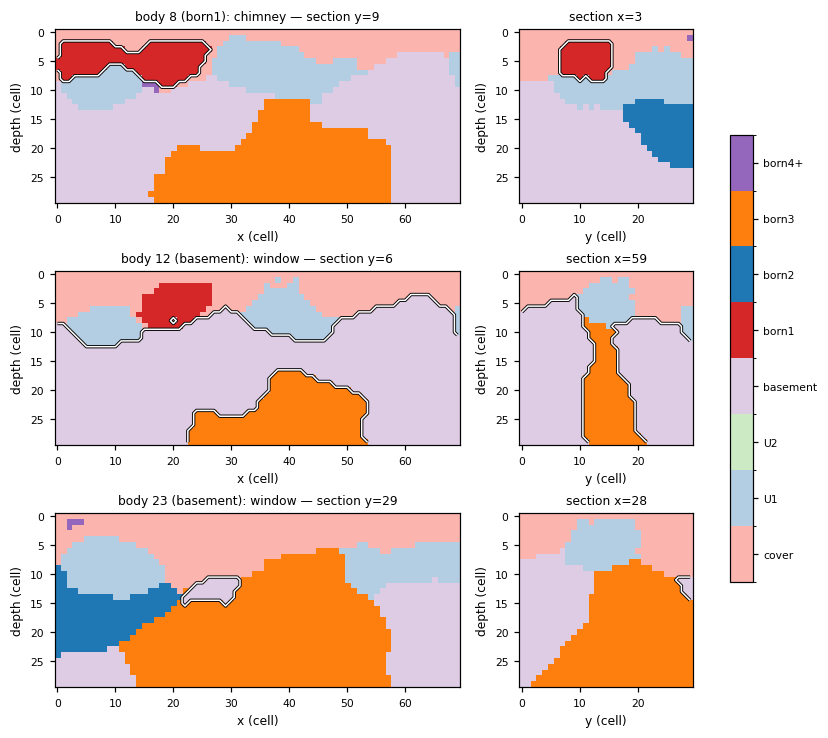

In [17]:
# Example model: among up to 200 models of the selection, the one realising EXAMPLE_MOTIF most clearly (highest
# typicality score; ties go to the largest body). Table of its bodies, and sections along x and y through each body
# carrying a motif. (body_labels: body ids of the model; `labels` keeps the cluster labels.)
i0, score = mp.pick_example(core, kw, EXAMPLE_MOTIF, n_sample=200, models=members)
c, G, body_labels, flags = ma.motif_counts(core[..., i0], return_graph=True, **kw)
if np.isnan(score):
    print(f"{EXAMPLE_MOTIF} does not occur in {where}: model #{i0} is shown instead")
print(f"model #{i0} (cluster {labels[i0]}, {chain_id[i0]}): {c['n_units']} units ({c['n_born']} born), "
      f"{c['n_bodies']} bodies, {c['fragment']} fragments dropped; typicality of its {EXAMPLE_MOTIF}: "
      f"{c['score_' + EXAMPLE_MOTIF]:.2f}")
display(mp.bodies_table(vw, i0, G, body_labels, flags))
mp.plot_flagged_bodies(vw, i0, G, body_labels, flags)

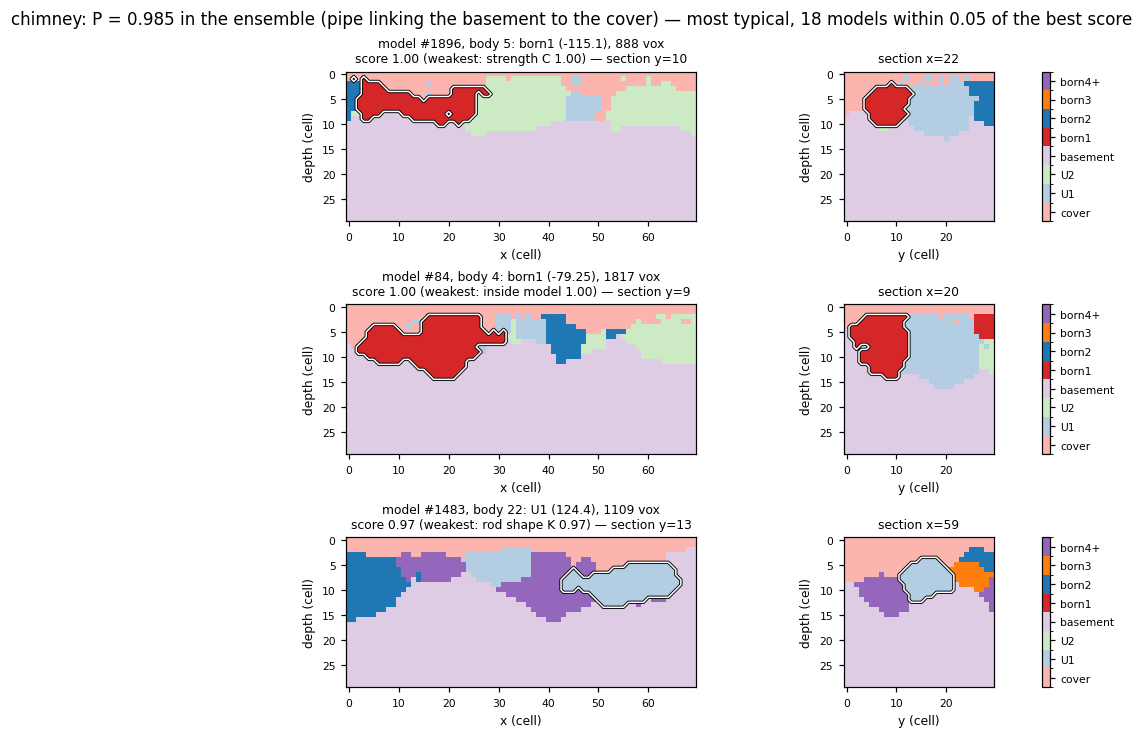

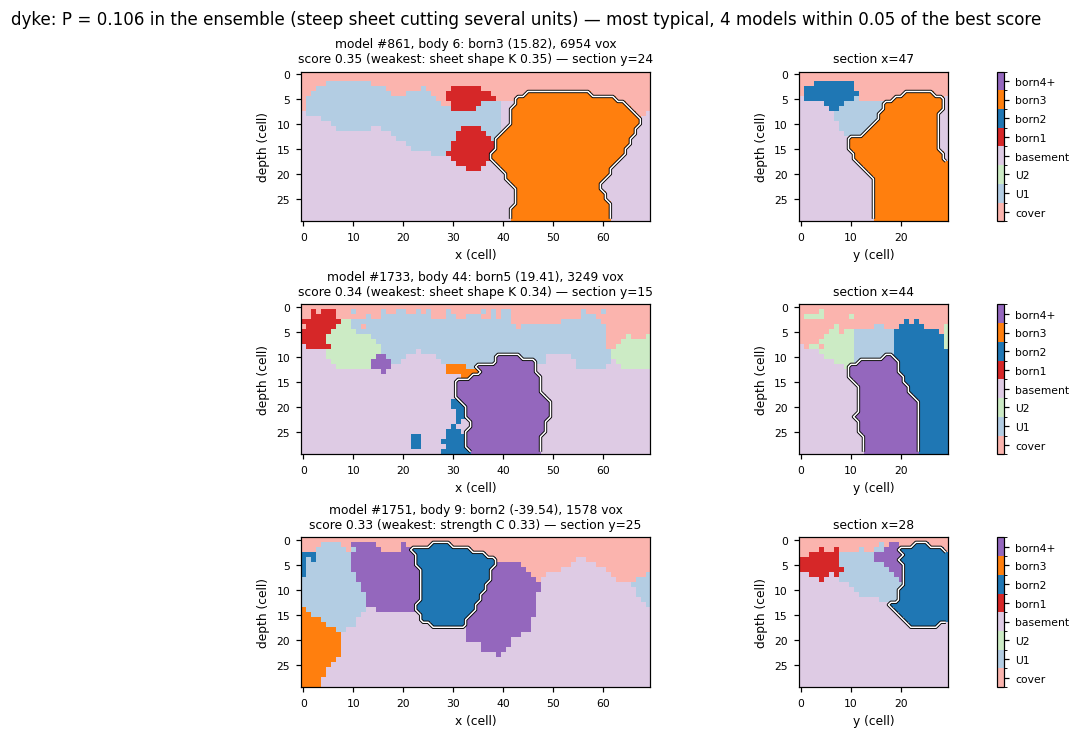

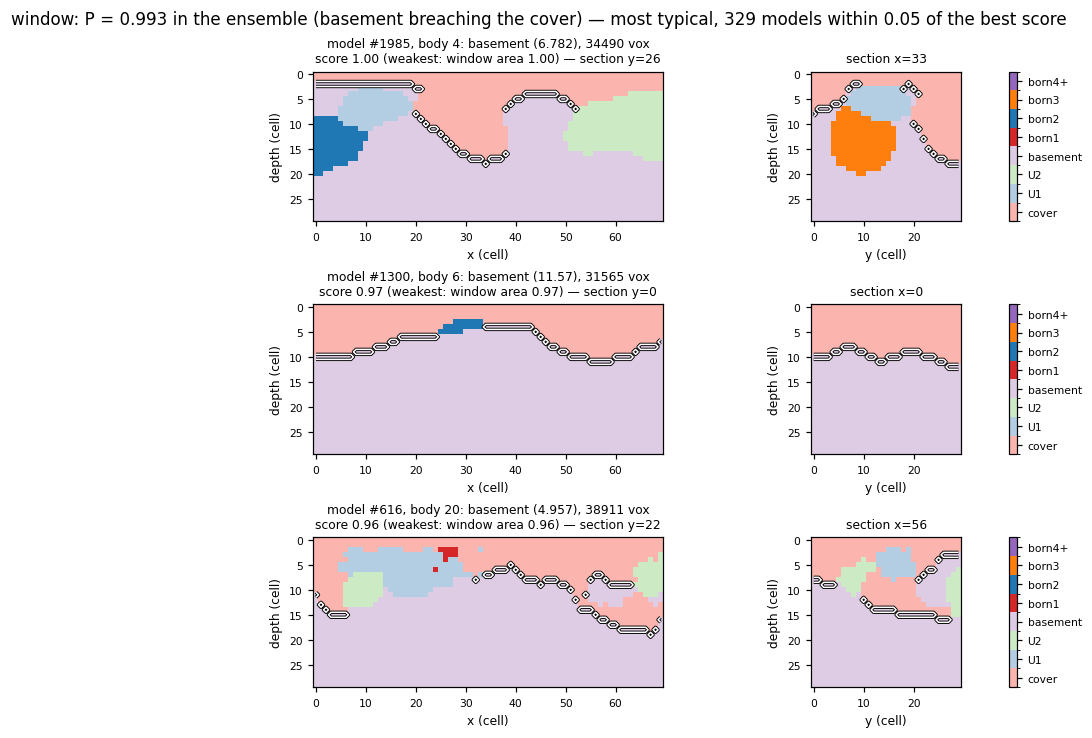

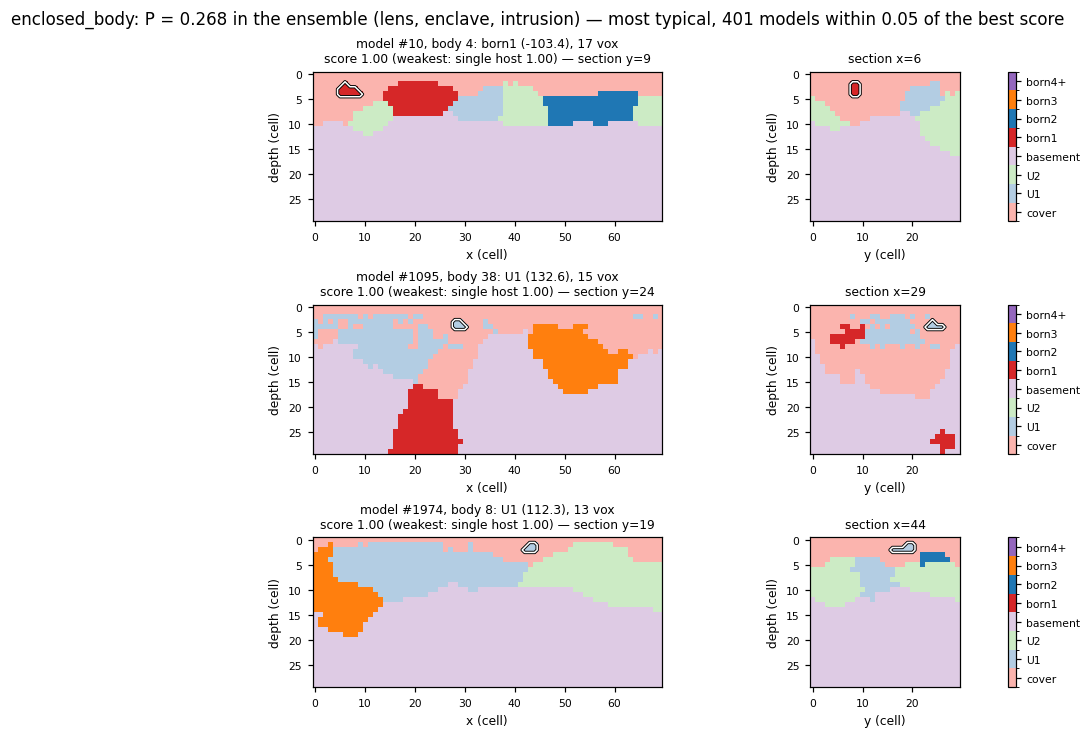

In [18]:
# Catalogue: N_EX example models per motif among the selected models, with the body realising the motif most clearly
# outlined (for window: the basement cells directly below the cover). Titles: model number (as in the viewer), score
# of the body and its weakest criterion.
mp.plot_motif_catalogue(vw, df_motifs, kw, motifs=SHOW_MOTIFS, n_ex=N_EX, select=SELECT, models=members, label=where)

,"P, ensemble"
chimney,0.985
dyke,0.106
window,0.993
enclosed_body,0.268


,at least one unit born,basement is one body,lens / enclosed body present,basement breaches the cover,pipe from basement into cover,steep dyke cutting several units,basement within 3 cells of surface
group,,,,,,,
chain 1,1.0,0.975,0.188,0.992,0.998,0.030,0.115
chain 2,1.0,0.780,0.285,1.000,0.995,0.062,0.300
chain 3,1.0,0.788,0.252,0.982,0.985,0.258,0.550
chain 4,1.0,0.800,0.270,0.990,0.970,0.085,0.448
chain 5,1.0,0.940,0.345,1.000,0.978,0.095,0.262


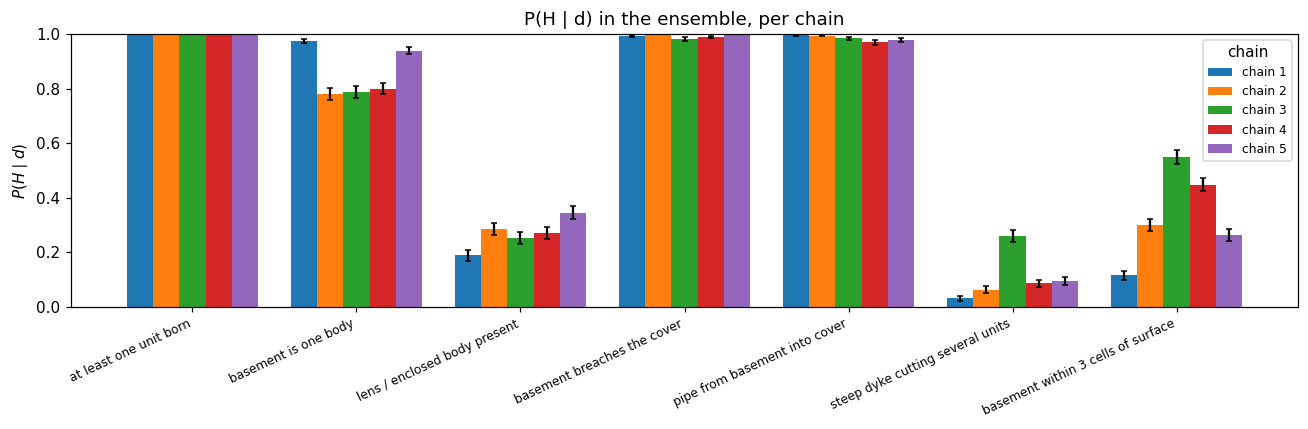

In [19]:
# P(motif present) in the selection, and P(H | d) per chain or per cluster (bars: binomial standard error).
display(cm.motif_probability_table(df_motifs, SHOW_MOTIFS, members, where).round(3))

rows, groups = cm.hypothesis_groups(members, labels, chain_id, GROUP_BY, MIN_SAMPLES, N_GROUPS)
d = df_motifs.iloc[rows].reset_index(drop=True)
H = {**cm.hypotheses(d, basement=K - 1, depth_cells=DEPTH_CELLS), **{k: f(d) for k, f in MY_HYPOTHESES.items()}}
tab_h = ma.hypothesis_table(H, groups=groups)
display(tab_h['P'].round(3))
mp.plot_hypotheses(tab_h, title=f'P(H | d) in {where}, per {GROUP_BY}', legend_title=GROUP_BY)

### Things to try

1. **One motif at a time.** Set `EXAMPLE_MOTIF` to `'dyke'`, then `'window'`, and compare the outlined bodies with the reading of each motif in the table above.
2. **Name a cluster.** In the motif viewer, choose a cluster whose heatmap row is red for `chimney` or `dyke`; set `CLUSTER` to its number and compare $P$ in the cluster with $P$ in the ensemble, then look at its examples. Do the members carry the same body, or different bodies that the encoder found similar?
3. **Chains or clusters.** With `GROUP_BY = 'chain'`, a hypothesis whose probability changes from chain to chain depends on the hyperparameters of the sampler; with `GROUP_BY = 'cluster'`, the hypotheses that separate the clusters are those the clustering has picked up.
4. **Thresholds.** Change `DEPTH_CELLS` (2, 3, 5): a hypothesis containing a number is conditional on it. In the motif settings cell, set e.g. `THR = dict(amin_link=8)` or `dict(c_min=1.5)`, re-run it, the motif-table cell and these cells: a probability that barely changes is a property of the models, one that follows the threshold is a property of the definition.
5. **Your own hypothesis.** Add one to `MY_HYPOTHESES`, e.g. `'pipe and dyke together': lambda d: (d['chimney'] > 0) & (d['dyke'] > 0)`, and compare it with the product of the two separate probabilities.
6. **A motif that was not validated.** Add `'cross_cutting'` to `SHOW_MOTIFS`: its examples include pipes as well as dykes, which is why the dyke hypothesis uses `dyke`.